# Bank Marketing Campaign Analysis Using Exploratory Data Analysis (EDA)

## 1. Introduction

Exploratory Data Analysis (EDA) helps us understand data, identify patterns, detect unusual values, and discover meaningful insights.

This project analyzes a bank marketing dataset to understand customer characteristics and campaign outcomes.

## 2. Objectives

- Examine dataset structure and data types.
- Identify missing values and duplicate records.
- Detect potential outliers.
- Create meaningful visualizations.
- Analyze customer subscription patterns.
- Summarize findings based on the data.

## 3. Dataset Description

The dataset contains information about bank customers, marketing campaign interactions, and term-deposit subscriptions.

**Dataset file:** `bank-full.csv`

**Dataset separator:** Semicolon (`;`)

## 4. Importing Libraries and Loading Dataset

In this step, we import the required Python libraries and load the Bank Marketing dataset for analysis.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

os.makedirs("visualizations", exist_ok=True)

df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 5. Dataset Overview

In this section, we examine the dataset's dimensions, column names, data types, and basic statistical information.

In [22]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

Number of rows and columns: (45211, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutc

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


## 6. Missing Values and Duplicate Records

In this section, we check for missing values and duplicate rows to understand the quality of the dataset.

In [23]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total missing values: 0
Duplicate rows: 0


## 7. Data Cleaning

In this section, we identify special values such as "unknown" and check for unusual values. We will preserve valid records and clean the data only when necessary.

In [24]:
# Count "unknown" values in each column
for col in df.select_dtypes(include="str").columns:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(f"{col}: {count} unknown values")

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check whether the dataset contains missing values
print("Total missing values:", df.isnull().sum().sum())

job: 288 unknown values
education: 1857 unknown values
contact: 13020 unknown values
poutcome: 36959 unknown values

Duplicate rows: 0
Total missing values: 0


## 8. Outlier Detection

Outliers are values that differ considerably from the rest of the data. The Interquartile Range (IQR) method is used to identify potential outliers in numerical columns.

In [25]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

age: 487 potential outliers
balance: 4729 potential outliers
day: 0 potential outliers
duration: 3235 potential outliers
campaign: 3064 potential outliers
pdays: 8257 potential outliers
previous: 8257 potential outliers


## 9. Feature Distribution Analysis

In this section, we visualize the distributions of numerical features to understand customer characteristics and campaign patterns.

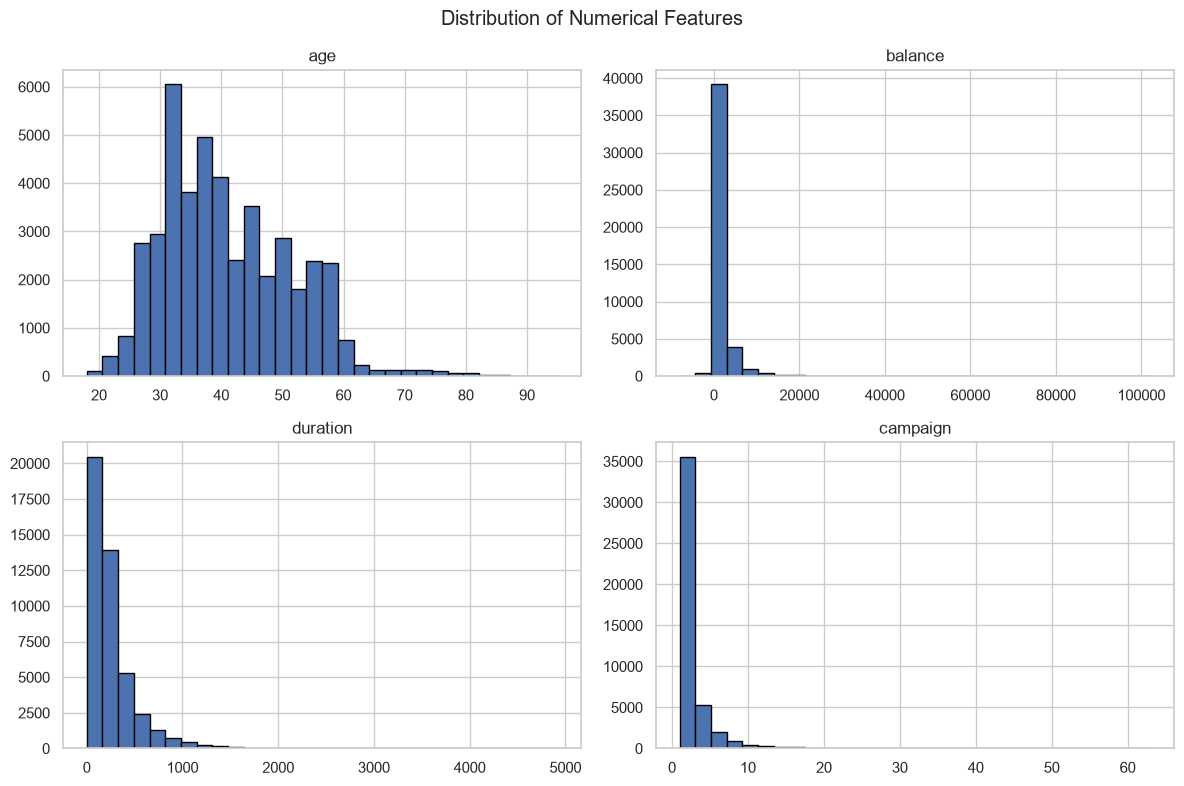

In [26]:
numeric_cols = ["age", "balance", "duration", "campaign"]

df[numeric_cols].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.savefig("visualizations/feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Boxplots for Outlier Visualization

Boxplots help visualize the spread of numerical data and identify potential outliers using the interquartile range.

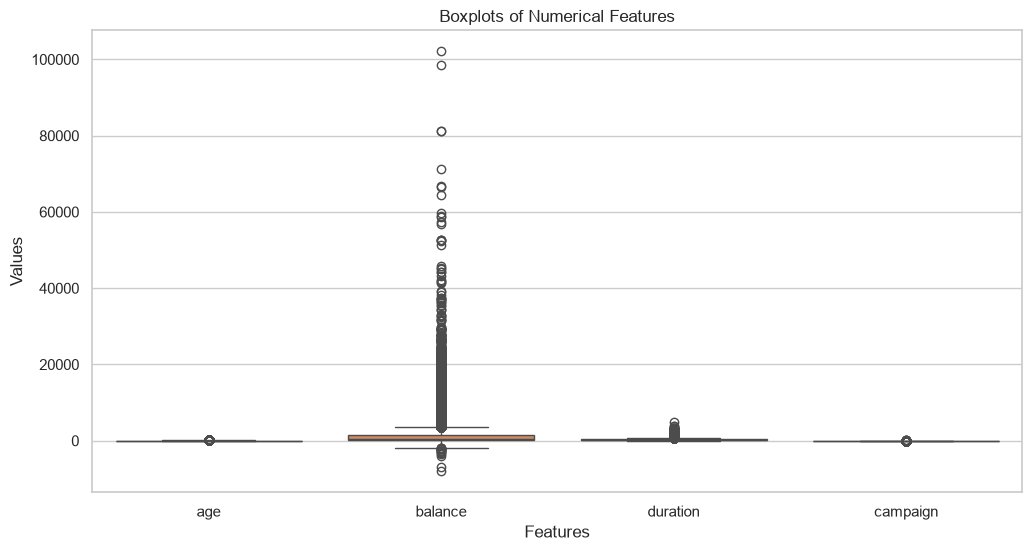

In [27]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[["age", "balance", "duration", "campaign"]])

plt.title("Boxplots of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.savefig(
    "visualizations/boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Correlation Heatmap

A correlation heatmap shows the strength and direction of relationships between numerical features. Correlation values range from -1 to +1.

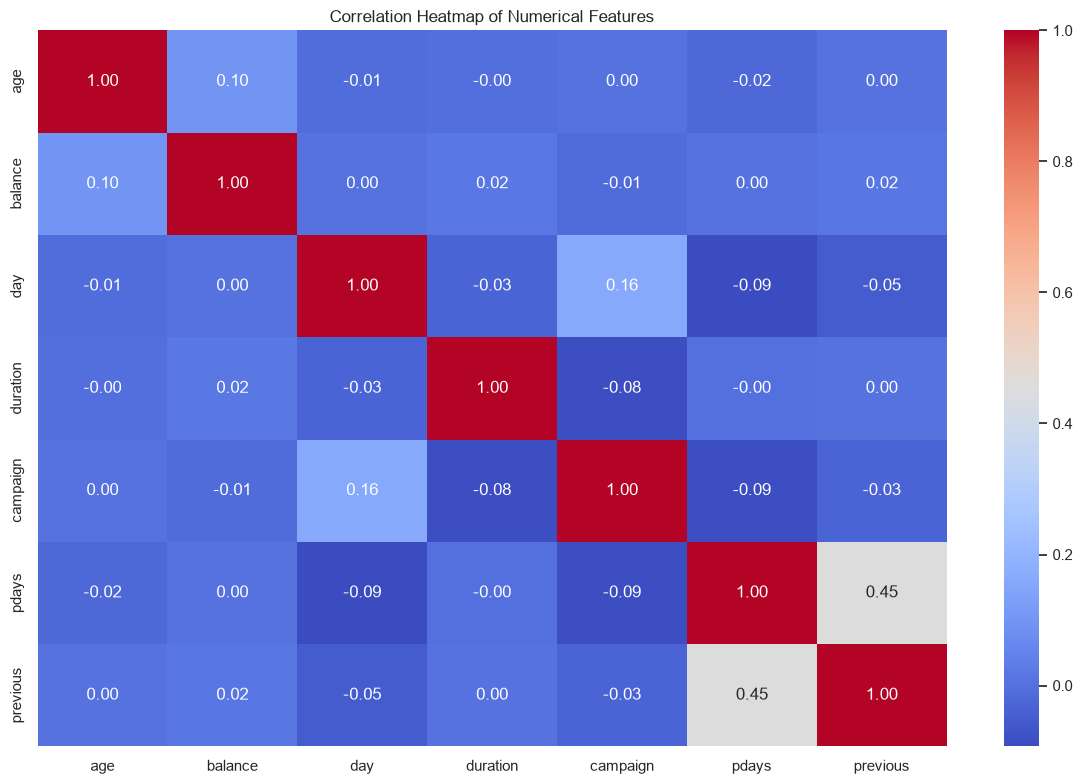

In [28]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.savefig(
    "visualizations/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Pairwise Scatter Plots

Pairwise scatter plots help visualize relationships between numerical features and identify possible patterns, trends, and unusual observations.

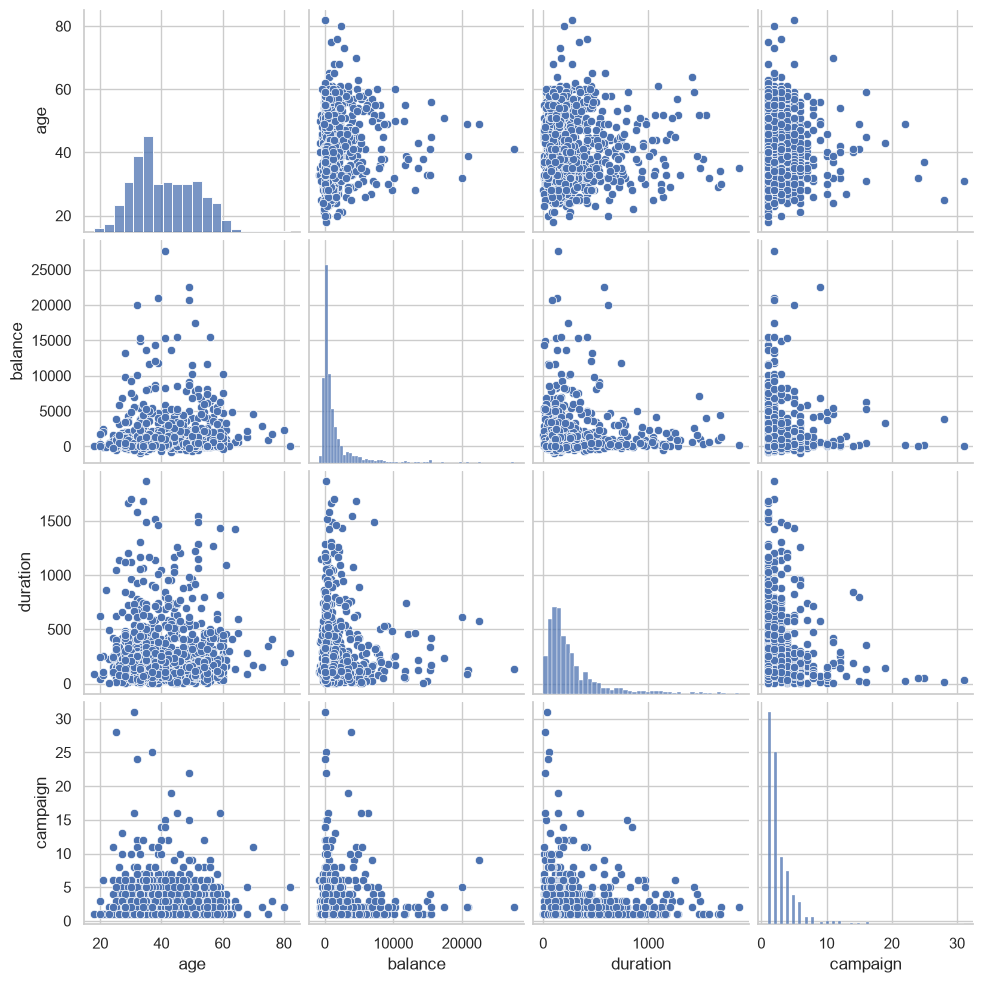

In [29]:

sample_df = df[["age", "balance", "duration", "campaign"]].sample(
    n=min(1000, len(df)),
    random_state=42
)

g = sns.pairplot(sample_df, diag_kind="hist")

g.savefig(
    "visualizations/pairwise_scatter_plots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 13. Term Deposit Subscription Analysis

This section analyzes the target variable `y` to understand how many customers subscribed to a term deposit and how many did not.

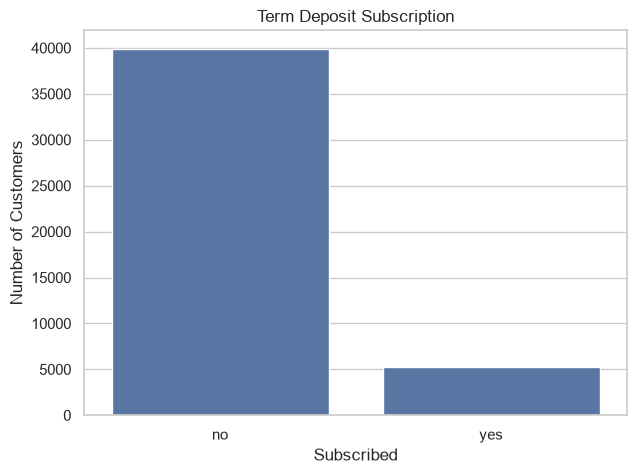

y
no     39922
yes     5289
Name: count, dtype: int64

Percentage:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")

plt.savefig(
    "visualizations/subscription_count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(df["y"].value_counts())
print("\nPercentage:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

## 14. Subscription Rate by Job

This section compares term-deposit subscription rates across different job categories to identify differences between customer groups.

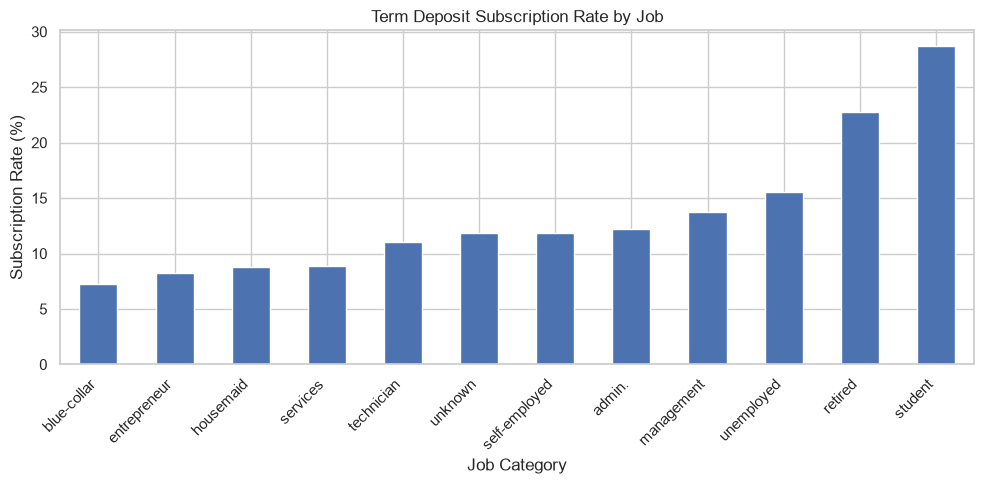

In [31]:
job_rate = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values()
)

job_rate.plot(kind="bar", figsize=(10, 5))

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job Category")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "visualizations/subscription_by_job.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Subscription Rate by Contact Method

This section compares term-deposit subscription rates across different contact methods used in the marketing campaign.

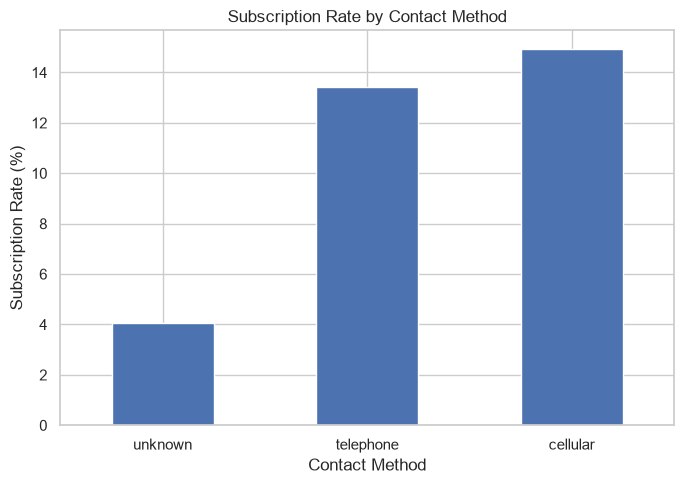

In [32]:
contact_rate = (
    df.groupby("contact")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values()
)

contact_rate.plot(kind="bar", figsize=(7, 5))

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "visualizations/subscription_by_contact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Subscription Rate by Month

This section compares term-deposit subscription rates across different months of the year.

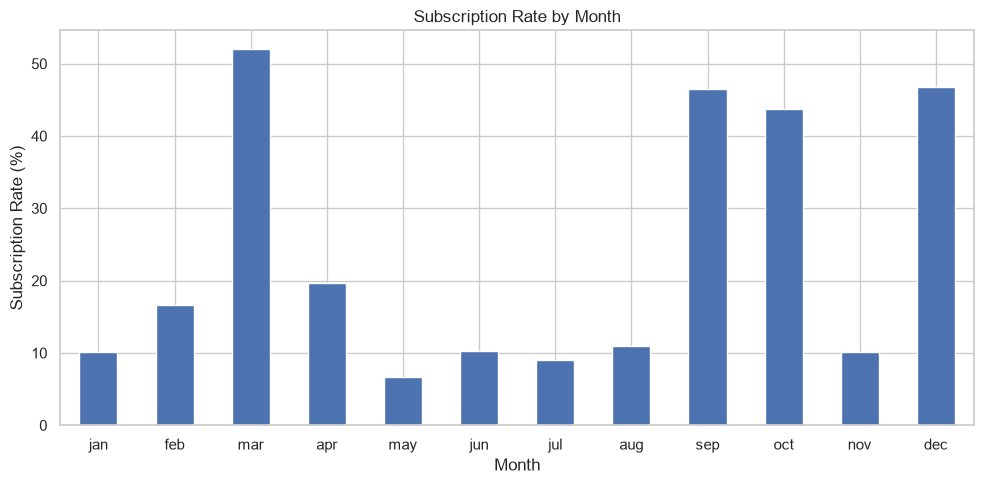

In [33]:
month_rate = (
    df.groupby("month")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_rate = month_rate.reindex(month_order).dropna()

month_rate.plot(kind="bar", figsize=(10, 5))

plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "visualizations/subscription_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Subscription Rate by Marital Status

This section compares term-deposit subscription rates among customers with different marital statuses.

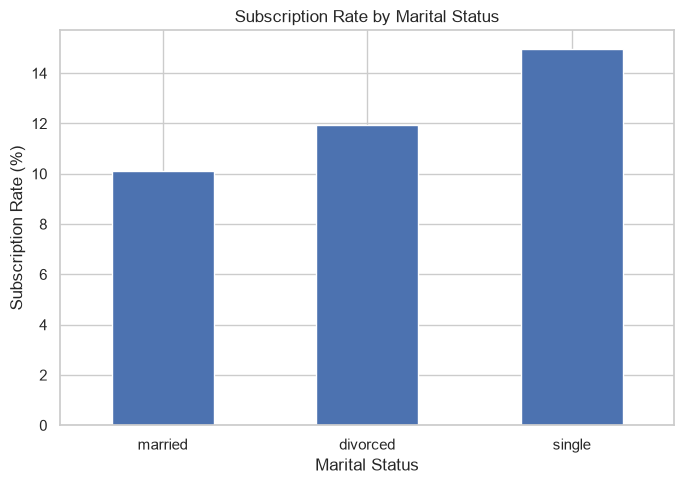

In [34]:
marital_rate = (
    df.groupby("marital")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values()
)

marital_rate.plot(kind="bar", figsize=(7, 5))

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "visualizations/subscription_by_marital.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Analytical Findings

This section summarizes the main observations from the dataset overview, data-quality checks, visualizations, and subscription analysis.

In [35]:
print("Total customers:", len(df))

print("\nSubscription counts:")
print(df["y"].value_counts())

print("\nSubscription percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

print("\nSubscription rate by job (%):")
print(
    (df.groupby("job")["y"]
       .apply(lambda x: (x == "yes").mean() * 100)
       .round(2)
       .sort_values(ascending=False))
)

print("\nSubscription rate by month (%):")
print(
    (df.groupby("month")["y"]
       .apply(lambda x: (x == "yes").mean() * 100)
       .round(2)
       .sort_values(ascending=False))
)

Total customers: 45211

Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Subscription rate by job (%):
job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: y, dtype: float64

Subscription rate by month (%):
month
mar    51.99
dec    46.73
sep    46.46
oct    43.77
apr    19.68
feb    16.65
aug    11.01
jun    10.22
nov    10.15
jan    10.12
jul     9.09
may     6.72
Name: y, dtype: float64


## Exporting Visualizations and Dataset

In this section, we save the analyzed dataset and visualization images for submission and future reference.

In [36]:
# Save the dataset
df.to_csv("cleaned_bank_marketing.csv", index=False)

# Check saved visualization files
print("Visualization files:")

for file in os.listdir("visualizations"):
    print(file)

print("\nDataset exported successfully!")

Visualization files:
boxplots.png
correlation_heatmap.png
feature_distributions.png
pairwise_scatter_plots.png
subscription_by_contact.png
subscription_by_job.png
subscription_by_marital.png
subscription_by_month.png
subscription_count.png

Dataset exported successfully!


### Observation

The dataset is exported as a CSV file, and the generated visualization images are stored in the visualizations folder. These files support the analysis and final project submission.

### Data Cleaning Justification

The dataset contains no missing values or duplicate rows, so no records were removed during the initial cleaning checks. Categorical values marked as `unknown` were retained because they represent unspecified information. Potential outliers were identified using the IQR method and retained because they may represent genuine customer data.